# 05 · Evaluación: prueba, subgrupos, umbral por vista, validación semisintética y sesión con el médico

**Proyecto:** Copiloto de triaje para neumonía en adultos · Proyecto Integrador, Maestría en Inteligencia Artificial (UEES), 2026.
**Cuaderno 5 de 5** (`01_exploracion` · `02_preprocesamiento` · `03_modelado` · `04_optimizacion` · `05_evaluacion`).

## Qué evalúa este cuaderno

Tres cosas distintas, y conviene no mezclarlas:

| Parte | Qué es | Qué mide | Qué NO mide |
| :--- | :--- | :--- | :--- |
| **Prueba de RSNA** (§2-§4) | el modelo de imagen sobre 3 811 placas **que no se usaron para entrenar, calibrar ni elegir el umbral** (844 con opacidad) | rendimiento de la imagen sola, global y por subgrupo, con intervalos de Wilson | exactitud clínica: la etiqueta de RSNA es *opacidad pulmonar*, un sustituto de la neumonía |
| **Validación semisintética** (§5) | las mismas placas reales, con la clínica **sorteada** con la distribución publicada de la puntuación de Heckerling y la dependencia entre clínica e imagen **supuesta** | si el sistema calcula lo que dice calcular y cómo se desvía la combinación bajo cada supuesto de dependencia | exactitud clínica en pacientes |
| **Sesión con un médico** (§6) | 24 casos, un médico general colaborador, dos lecturas | acuerdo con un evaluador y utilidad percibida del pre-informe | generalización a otros médicos o a otros casos |

El cuaderno **solo lee agregados que ya están en el repositorio** (`app/assets/metricas.json`, `docs/validacion-semisintetica/resultados_simulacion.json` y `sesion.json`): no necesita los datos de RSNA ni los pesos y se ejecuta en segundos. Todo lo que se **deriva** de ellos (recuentos, cocientes, precios) se rotula como derivado.

Se cuenta **tal cual salió**, incluido lo que no sale bien: es lo que pide la evaluación y es lo único defendible.

In [1]:
import json
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def raiz_del_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "pyproject.toml").is_file() and (carpeta / "src" / "copiloto_triaje").is_dir():
            return carpeta
    raise SystemExit("Abre el cuaderno dentro del repositorio: no se encontró pyproject.toml.")


REPO = raiz_del_repositorio()
for carpeta in ("src", "app"):
    sys.path.insert(0, str(REPO / carpeta))

import generar_metricas as gm                       # noqa: E402  app/generar_metricas.py (wilson, las cuentas)
from copiloto_triaje.modelo.reporte import CRITERIOS_ACEPTACION  # noqa: E402

DOCS = REPO / "docs" / "validacion-semisintetica"
M = json.loads((REPO / "app" / "assets" / "metricas.json").read_text(encoding="utf-8"))
SIM = json.loads((DOCS / "resultados_simulacion.json").read_text(encoding="utf-8"))
SESION = json.loads((DOCS / "sesion.json").read_text(encoding="utf-8"))

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("¿Las métricas y la simulación hablan del mismo modelo y de las mismas puntuaciones?",
      M["pesos_sha256"] == SIM["insumos"]["pesos_sha256"] and M["puntuaciones_sha256"] == SIM["insumos"]["crudas_sha256"])
print(f"métricas generadas el {M['generado']}; umbral global {M['umbral']}; umbrales por vista {M['umbrales_por_vista']}")

Python 3.13.16 | numpy 2.5.2 | pandas 3.0.5
¿Las métricas y la simulación hablan del mismo modelo y de las mismas puntuaciones? True
métricas generadas el 2026-10-05; umbral global 0.4258; umbrales por vista {'PA': 0.1798, 'AP': 0.5815}


## 1. Criterios con los que se juzga

Los criterios de aceptación del proyecto (spec §2) distinguen **mínimo** de **objetivo**, y son los de `CRITERIOS_ACEPTACION`. A ellos se suma el de la Semana 1 para la sesión con el médico: **kappa ponderado ≥ 0,4** (acuerdo al menos moderado).

Regla de lectura que se aplica en todo el cuaderno: **un criterio se da por cumplido solo si el intervalo de confianza entero queda a su lado**; si el intervalo contiene el valor, **no se puede decir**. Una estimación puntual por encima del mínimo no basta.

In [2]:
print(pd.DataFrame(CRITERIOS_ACEPTACION, columns=["criterio", "clave", "mínimo", "objetivo"]).drop(columns="clave").to_string(index=False))
print("kappa ponderado de la sesión con el médico: mínimo 0,4 (Semana 1)")

             criterio  mínimo  objetivo
Recall (sensibilidad)    0.80      0.85
        Especificidad    0.70      0.75
              AUC-ROC    0.85      0.88
kappa ponderado de la sesión con el médico: mínimo 0,4 (Semana 1)


## 2. El conjunto de prueba, en global

Se mide con el modelo desplegado y su umbral (0,4258, elegido en validación; cuaderno 04, §7). El AUC no depende del umbral. Los recuentos de la matriz de confusión son **derivados** (tasa × n) y se comprueban recalculando los intervalos de Wilson con la función del proyecto.

In [3]:
g = M["global"]
pos, neg = g["positivos"], g["n"] - g["positivos"]
tp, tn = round(g["recall"] * pos), round(g["especificidad"] * neg)
fn, fp = pos - tp, neg - tn

# ¿los intervalos del JSON son los de Wilson de estos recuentos?
ic_recall, ic_espec = gm.wilson(tp, pos), gm.wilson(tn, neg)
coinciden = (np.allclose(ic_recall, g["recall_ic"], atol=1e-6) and np.allclose(ic_espec, g["especificidad_ic"], atol=1e-6))
print(f"{g['n']:,} placas de prueba, {pos} con opacidad ({pos / g['n']:.2%}). Intervalos de Wilson recalculados = los del JSON: {coinciden}\n")


def estado(valor, ic, minimo, objetivo):
    if ic is None:
        return "sin IC"
    if ic[0] >= objetivo:
        return "objetivo"
    if ic[0] >= minimo:
        return "mínimo"
    if ic[1] < minimo:
        return "NO cumple"
    return "no se puede decir (el IC contiene el mínimo)"


filas = []
for nombre, clave, minimo, objetivo in CRITERIOS_ACEPTACION:
    ic = g.get(f"{clave}_ic")
    punto = "objetivo" if g[clave] >= objetivo else ("mínimo" if g[clave] >= minimo else "NO cumple")
    filas.append({"criterio": nombre, "valor": round(g[clave], 4),
                  "IC 95 % (Wilson)": f"{ic[0]:.3f}-{ic[1]:.3f}" if ic else "(el JSON no trae IC del AUC)",
                  "mínimo / objetivo": f"{minimo} / {objetivo}", "por el valor": punto, "por el IC entero": estado(g[clave], ic, minimo, objetivo)})
print(pd.DataFrame(filas).to_string(index=False))

print(f"\nMatriz de confusión (derivada): TP {tp}, FN {fn}, TN {tn}, FP {fp}")
print(f"  precisión (valor predictivo positivo) en la prueba: {tp / (tp + fp):.3f}   valor predictivo negativo: {tn / (tn + fn):.3f}")
previo_local = SESION["prevalencia_sesion"]
ppv_local = g["recall"] * previo_local / (g["recall"] * previo_local + (1 - g["especificidad"]) * (1 - previo_local))
print(f"  si la prevalencia fuera la local declarada ({previo_local:.4f}) y el recall y la especificidad se mantuvieran: "
      f"valor predictivo positivo {ppv_local:.3f}  (aritmética de Bayes, no una medición)")

3,811 placas de prueba, 844 con opacidad (22.15%). Intervalos de Wilson recalculados = los del JSON: True

             criterio  valor             IC 95 % (Wilson) mínimo / objetivo por el valor                             por el IC entero
Recall (sensibilidad) 0.8815                  0.858-0.902        0.8 / 0.85     objetivo                                     objetivo
        Especificidad 0.7024                  0.686-0.719        0.7 / 0.75       mínimo no se puede decir (el IC contiene el mínimo)
              AUC-ROC 0.8848 (el JSON no trae IC del AUC)       0.85 / 0.88     objetivo                                       sin IC

Matriz de confusión (derivada): TP 744, FN 100, TN 2084, FP 883
  precisión (valor predictivo positivo) en la prueba: 0.457   valor predictivo negativo: 0.954
  si la prevalencia fuera la local declarada (0.1466) y el recall y la especificidad se mantuvieran: valor predictivo positivo 0.337  (aritmética de Bayes, no una medición)


### Comparación con un baseline

¿Qué se obtendría sin el modelo? Hay tres referencias, y ninguna es un modelo clínico:

- **Al azar:** AUC 0,5.
- **Un «clasificador» que solo mira la vista de la placa** (marca como opacidad toda placa AP): se puede calcular **con los propios agregados** de las dos vistas, porque la vista es el sesgo más fuerte del conjunto. Si el modelo valiera lo que vale solo por la vista, estaría aquí.
- **La primera corrida del proyecto** (224 px, MobileNetV3-Large; `docs/mejoras-2026-09-21.md` §1), antes de las mejoras. No es estrictamente comparable: otra población (sin filtro de edad) y otra regla de umbral.

In [4]:
sub = {s["nombre"]: s for s in M["subgrupos"]}
pa, ap = sub["Placa PA (de pie)"], sub["Placa AP (portátil)"]
tp_ap = round(ap["recall"] * ap["positivos"])
fp_ap = ap["n"] - ap["positivos"] - round(ap["especificidad"] * (ap["n"] - ap["positivos"]))
fp_ap_vista = (ap["n"] - ap["positivos"])          # con la regla «AP = opacidad», todas las AP sin opacidad son falsas alarmas
recall_vista = ap["positivos"] / g["positivos"]                           # las positivas que son AP
espec_vista = 1 - fp_ap_vista / neg                                       # los negativos que NO son AP
auc_vista = (recall_vista + espec_vista) / 2                              # AUC de un clasificador binario
comparacion = pd.DataFrame([
    {"referencia": "al azar", "AUC": 0.5, "recall": None, "especificidad": None},
    {"referencia": "solo la vista (AP = opacidad)", "AUC": round(auc_vista, 3), "recall": round(recall_vista, 3), "especificidad": round(espec_vista, 3)},
    {"referencia": "1.ª corrida del proyecto (docs/mejoras, §1)", "AUC": 0.845, "recall": 0.766, "especificidad": 0.764},
    {"referencia": "modelo desplegado", "AUC": round(g["auc"], 3), "recall": round(g["recall"], 3), "especificidad": round(g["especificidad"], 3)},
])
print(comparacion.to_string(index=False))
print(f"\nDentro de cada vista la vista no informa (es constante), así que el AUC dentro de cada una es la prueba de que el modelo "
      f"ordena por algo más que la vista: PA {pa['auc']:.3f}, AP {ap['auc']:.3f}.")

                                 referencia   AUC  recall  especificidad
                                    al azar 0.500     NaN            NaN
              solo la vista (AP = opacidad) 0.698   0.761          0.635
1.ª corrida del proyecto (docs/mejoras, §1) 0.845   0.766          0.764
                          modelo desplegado 0.885   0.882          0.702

Dentro de cada vista la vista no informa (es constante), así que el AUC dentro de cada una es la prueba de que el modelo ordena por algo más que la vista: PA 0.882, AP 0.829.


**Lectura.**

- **Por el valor puntual cumple los tres mínimos y dos de los tres objetivos** (recall y AUC). Por el **intervalo entero**, el recall cumple incluso el objetivo (el límite inferior, 0,858, supera 0,85). La **especificidad** (0,702) supera el mínimo solo en el valor puntual: su intervalo (0,686 a 0,719) **contiene 0,70**, así que con 3 811 placas **no se puede afirmar** que lo supere, solo que está en él. El objetivo de especificidad (0,75) **no se alcanza**, y ya se sabía que no se puede alcanzar a la vez que el recall objetivo (cuaderno 04, §7).
- **Frente al baseline:** el modelo mejora con claridad al azar y a un clasificador que solo mira la vista (AUC en torno a 0,70 con la regla «AP = opacidad»), y ordena por algo más que la vista: dentro de cada vista el AUC sigue siendo alto. Respecto a la primera corrida, mejora el recall y el AUC (y la especificidad baja, a un valor aún por encima del mínimo), con la salvedad ya dicha de que no es una comparación estricta.
- **La precisión es baja:** con la prevalencia de la prueba (22 %), poco menos de la mitad de las placas marcadas tienen opacidad; con la prevalencia local declarada, aproximadamente una de cada tres. Es un **cribado**, no un diagnóstico: el profesional decide siempre.

## 3. Por subgrupos

Los 13 subgrupos son los de la tabla 2 del workshop de la Semana 4: todas las placas, sexo, tres tramos de edad, vista y los cruces de la vista con el sexo y la edad. Todos con **el mismo umbral global** (0,4258). Los intervalos son de Wilson al 95 %.

In [5]:
minimo_recall, minimo_espec = 0.80, 0.70
filas = []
for s in M["subgrupos"]:
    filas.append({
        "subgrupo": s["nombre"], "n": s["n"], "positivas": s["positivos"], "prevalencia": round(s["positivos"] / s["n"], 3),
        "AUC": round(s["auc"], 3),
        "recall (IC)": f"{s['recall']:.3f} ({s['recall_ic'][0]:.3f}-{s['recall_ic'][1]:.3f})",
        "frente a 0,80": estado(s["recall"], s["recall_ic"], minimo_recall, 0.85).replace(" (el IC contiene el mínimo)", ""),
        "espec. (IC)": f"{s['especificidad']:.3f} ({s['especificidad_ic'][0]:.3f}-{s['especificidad_ic'][1]:.3f})",
        "frente a 0,70": estado(s["especificidad"], s["especificidad_ic"], minimo_espec, 0.75).replace(" (el IC contiene el mínimo)", "")})
print(pd.DataFrame(filas).to_string(index=False))

           subgrupo    n  positivas  prevalencia   AUC         recall (IC)     frente a 0,80         espec. (IC)     frente a 0,70
   Todas las placas 3811        844        0.221 0.885 0.882 (0.858-0.902)          objetivo 0.702 (0.686-0.719) no se puede decir
            Mujeres 1677        353        0.210 0.886 0.867 (0.827-0.898)            mínimo 0.721 (0.697-0.745) no se puede decir
            Hombres 2134        491        0.230 0.883 0.892 (0.862-0.917)          objetivo 0.687 (0.664-0.709) no se puede decir
       18 a 39 años 1081        263        0.243 0.902 0.901 (0.859-0.932)          objetivo 0.726 (0.695-0.756) no se puede decir
       40 a 59 años 1766        388        0.220 0.889 0.894 (0.860-0.921)          objetivo 0.695 (0.670-0.719) no se puede decir
      60 años o más  964        193        0.200 0.854 0.829 (0.770-0.876) no se puede decir 0.690 (0.656-0.722) no se puede decir
  Placa PA (de pie) 2087        202        0.097 0.882 0.693 (0.626-0.753)         

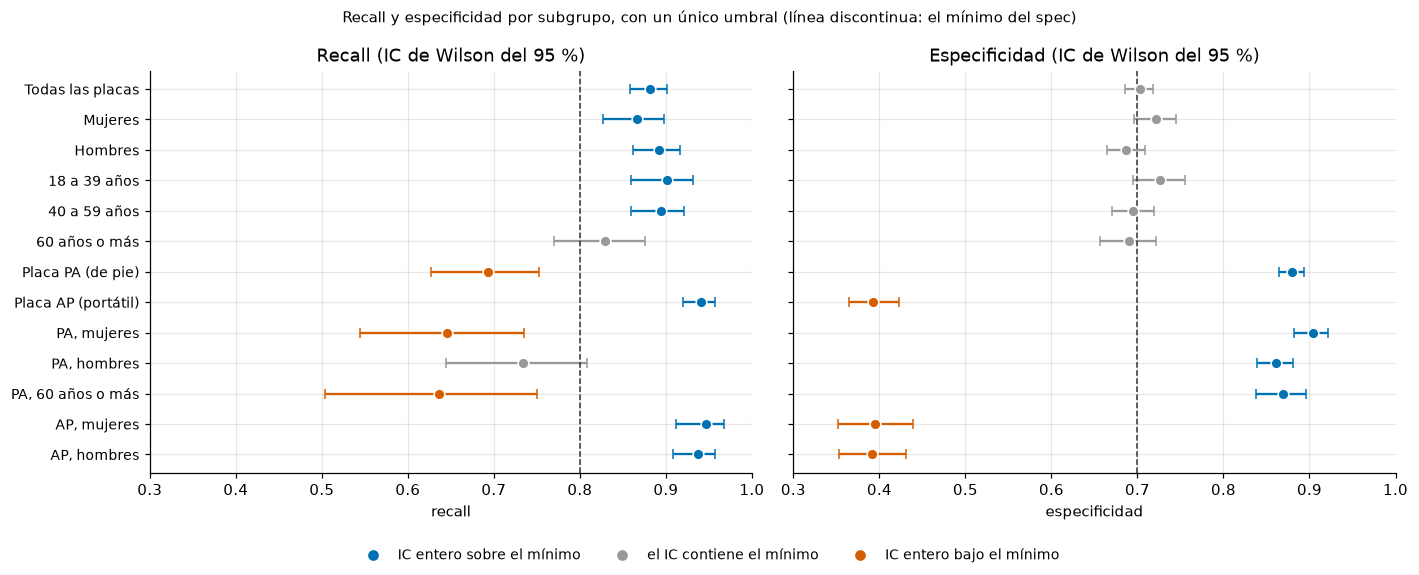

In [6]:
nombres = [s["nombre"] for s in M["subgrupos"]][::-1]
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for eje, metrica, minimo, titulo in ((ejes[0], "recall", 0.80, "Recall"), (ejes[1], "especificidad", 0.70, "Especificidad")):
    for y, s in enumerate(M["subgrupos"][::-1]):
        ic = s[f"{metrica}_ic"]
        entero_debajo = ic[1] < minimo
        color = "#D55E00" if entero_debajo else ("#0072B2" if ic[0] >= minimo else "#999999")
        eje.errorbar(s[metrica], y, xerr=[[s[metrica] - ic[0]], [ic[1] - s[metrica]]], fmt="o", color=color, ms=7,
                     capsize=3, mec="white", mew=1)
    eje.axvline(minimo, color="#333333", ls="--", lw=1)
    eje.set(title=f"{titulo} (IC de Wilson del 95 %)", xlim=(0.3, 1.0), xlabel=titulo.lower())
ejes[0].set_yticks(range(len(nombres)), nombres, fontsize=9)
leyenda = [plt.Line2D([], [], marker="o", ls="", color=c, label=t) for c, t in (
    ("#0072B2", "IC entero sobre el mínimo"), ("#999999", "el IC contiene el mínimo"), ("#D55E00", "IC entero bajo el mínimo"))]
fig.legend(handles=leyenda, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Recall y especificidad por subgrupo, con un único umbral (línea discontinua: el mínimo del spec)", fontsize=10)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [7]:
def se_solapan(a_, b_):
    return max(a_[0], b_[0]) <= min(a_[1], b_[1])


for etiqueta, uno, otro in (("sexo", "Mujeres", "Hombres"), ("edad", "18 a 39 años", "60 años o más"), ("vista", "Placa PA (de pie)", "Placa AP (portátil)")):
    x, y = sub[uno], sub[otro]
    print(f"{etiqueta}: {uno} frente a {otro}")
    for metrica in ("recall", "especificidad"):
        print(f"    {metrica:<14} {x[metrica]:.3f} frente a {y[metrica]:.3f}  ->  "
              + ("los intervalos SE SOLAPAN: no se puede afirmar diferencia" if se_solapan(x[f"{metrica}_ic"], y[f"{metrica}_ic"])
                 else "los intervalos NO se solapan: diferencia clara"))
    print(f"    AUC            {x['auc']:.3f} frente a {y['auc']:.3f}  (el JSON no trae intervalo del AUC: solo la diferencia puntual)")

sexo: Mujeres frente a Hombres
    recall         0.867 frente a 0.892  ->  los intervalos SE SOLAPAN: no se puede afirmar diferencia
    especificidad  0.721 frente a 0.687  ->  los intervalos SE SOLAPAN: no se puede afirmar diferencia
    AUC            0.886 frente a 0.883  (el JSON no trae intervalo del AUC: solo la diferencia puntual)
edad: 18 a 39 años frente a 60 años o más
    recall         0.901 frente a 0.829  ->  los intervalos SE SOLAPAN: no se puede afirmar diferencia
    especificidad  0.726 frente a 0.690  ->  los intervalos SE SOLAPAN: no se puede afirmar diferencia
    AUC            0.902 frente a 0.854  (el JSON no trae intervalo del AUC: solo la diferencia puntual)
vista: Placa PA (de pie) frente a Placa AP (portátil)
    recall         0.693 frente a 0.941  ->  los intervalos NO se solapan: diferencia clara
    especificidad  0.880 frente a 0.393  ->  los intervalos NO se solapan: diferencia clara
    AUC            0.882 frente a 0.829  (el JSON no trae intervalo

**Lectura.**

- **La vista es la diferencia que importa, y es enorme.** Con un único umbral, en las placas **PA** el recall es 0,69 (el intervalo entero queda bajo 0,80: no cumple el mínimo) y la especificidad 0,88; en las **AP**, el recall 0,94 y la especificidad 0,39 (intervalo entero bajo 0,70: no cumple). Los dos grupos son del orden de la mitad de la prueba cada uno, y sus intervalos no se solapan. El modelo se porta como dos clasificadores distintos según la vista.
- **El AUC dentro de cada vista** sigue siendo útil (PA 0,88, AP 0,83): ordena bien en las dos, pero **peor en AP**, la vista con más opacidades y donde el umbral global marca de más.
- **Sexo:** sin diferencia que se pueda afirmar (los intervalos de mujeres y hombres se solapan, tanto en recall como en especificidad).
- **Edad:** el tramo de **60 años o más** es el más flojo (recall 0,83, AUC 0,85, el más bajo de los tres tramos), pero su intervalo de recall se solapa con el de 18 a 39 años: la diferencia **no se puede afirmar** con estas muestras. Tampoco se puede decir que cumpla el mínimo de recall (el intervalo contiene 0,80).
- **Los subgrupos más pequeños** tienen intervalos anchos: en PA con mujeres y en PA con 60 años o más el intervalo de recall queda **entero por debajo de 0,80**, y en PA con hombres lo contiene. Ahí el sistema **no demuestra** cumplir el mínimo.
- **Lo que esto no es:** un análisis de equidad completo. Los metadatos que usa el proyecto son edad, sexo y vista, así que solo se pudo mirar eso: no se evaluó por raza, etnia ni centro, y no se probó en otra población.

## 4. El umbral por vista: qué cuesta

La mitigación del sesgo de la vista (cuaderno 04, §8) es un umbral por vista (PA 0,1798 y AP 0,5815, elegidos en validación y evaluados aquí en prueba), **apagada por defecto**. Esta es la cuenta de lo que compra y de lo que cuesta, en recuentos **derivados** (tasa × n) para que se vea qué significa en placas y no solo en proporciones.

In [8]:
efecto = M["umbral_por_vista_en_prueba"]
filas = []
for grupo in ("PA", "AP", "global"):
    uno, dos = efecto["un_umbral"][grupo], efecto["dos_umbrales"][grupo]
    positivas, negativas = uno["positivos"], uno["n"] - uno["positivos"]
    fn_uno, fn_dos = positivas - round(uno["recall"] * positivas), positivas - round(dos["recall"] * positivas)
    fp_uno, fp_dos = negativas - round(uno["especificidad"] * negativas), negativas - round(dos["especificidad"] * negativas)
    filas.append({"grupo": grupo, "n": uno["n"],
                  "recall": f"{uno['recall']:.3f} -> {dos['recall']:.3f}", "especificidad": f"{uno['especificidad']:.3f} -> {dos['especificidad']:.3f}",
                  "opacidades que se escapan": f"{fn_uno} -> {fn_dos} ({fn_dos - fn_uno:+d})",
                  "falsas alarmas": f"{fp_uno} -> {fp_dos} ({fp_dos - fp_uno:+d})"})
print("Un umbral -> umbral por vista (PRUEBA, recuentos derivados de las tasas):")
print(pd.DataFrame(filas).to_string(index=False))
dg_uno, dg_dos = efecto["un_umbral"]["global"], efecto["dos_umbrales"]["global"]
print(f"\nGlobal: la especificidad pasa de {dg_uno['especificidad']:.3f} a {dg_dos['especificidad']:.3f} "
      f"(intervalo {dg_dos['especificidad_ic'][0]:.3f}-{dg_dos['especificidad_ic'][1]:.3f}): "
      f"{'por debajo' if dg_dos['especificidad_ic'][1] < 0.70 else 'no por debajo'} del mínimo de 0,70.")

Un umbral -> umbral por vista (PRUEBA, recuentos derivados de las tasas):
 grupo    n         recall  especificidad opacidades que se escapan     falsas alarmas
    PA 2087 0.693 -> 0.891 0.880 -> 0.646            62 -> 22 (-40)  226 -> 667 (+441)
    AP 1724 0.941 -> 0.888 0.393 -> 0.561            38 -> 72 (+34)  657 -> 475 (-182)
global 3811 0.882 -> 0.889 0.702 -> 0.615            100 -> 94 (-6) 883 -> 1142 (+259)

Global: la especificidad pasa de 0.702 a 0.615 (intervalo 0.597-0.632): por debajo del mínimo de 0,70.


**Lectura.** El umbral por vista **iguala el recall** de las dos vistas (0,89 y 0,89) y **reparte la especificidad** (la de PA baja de 0,88 a 0,65 y la de AP sube de 0,39 a 0,56), pero la cuenta global es esta: **rescata 6 opacidades** (de 100 que se escapan a 94) **a cambio de 259 falsas alarmas más** (de 883 a 1 142), unas 43 por cada una, y deja la especificidad global (0,62, intervalo entero) **por debajo del mínimo de 0,70**. Por vista: en PA rescata 40 opacidades por 441 falsas alarmas más; en AP **pierde 34** y ahorra 182 falsas alarmas. No se resuelve el problema de fondo (la vista predice la etiqueta en el conjunto): se cambia dónde cae el error. Por eso sigue apagado y la decisión de activarlo queda en manos del equipo.

## 5. La validación semisintética de la combinación de clínica e imagen

El producto no entrega solo la probabilidad de la imagen: **combina** la imagen con la puntuación clínica de Heckerling multiplicando razones de verosimilitud, y declara una **horquilla** entre el extremo de independencia y el extremo conservador (dependencia total). No existe un conjunto de pacientes reales con imagen y clínica con el que validarlo, así que se hizo una **simulación semisintética**:

- **Real:** las 3 811 placas de prueba y su etiqueta, con las puntuaciones congeladas del modelo desplegado y su calibrador.
- **Sorteado:** a cada placa se le sortea la puntuación de Heckerling dada su etiqueta, con las frecuencias **publicadas** (no se inventa la exactitud de la regla).
- **Supuesto:** la dependencia entre clínica e imagen: nula en el escenario 0A y barrida en una rejilla de 5 × 5 valores de ρ1 (entre las placas con opacidad) y ρ0 (entre las que no la tienen) de 0 a 0,6. Un ρ de 0,6 es un caso extremo, no plausible: se incluye para acotar.
- **El oráculo** es la posterior que da el propio generador con la información que ve el sistema; es la verdad de la simulación, no la de un paciente.

**Nada de esto mide exactitud clínica en pacientes.** Lo que sí puede decir es si el sistema calcula lo que dice calcular y cuánto se desvía bajo cada supuesto.

In [9]:
celdas = {c["nombre"]: c for c in SIM["celdas"]}
c0 = celdas["0A"]
iv = c0["intervalos"]
print(f"Escenario 0A (dependencia nula), {c0['recuentos']['asma_conocida']:,} casos con el asma conocida, {SIM['parametros']['replicas']} réplicas de bootstrap:\n")
filas = []
for clave, nombre in (("imagen", "imagen sola"), ("clinica", "clínica sola"), ("independencia", "combinación, independencia"),
                      ("conservador", "combinación, extremo conservador")):
    m = c0["modelos"][clave]
    def con_ic(campo, decimales=3):
        lo, hi = iv[f"modelos.{clave}.{campo}"]
        return f"{m[campo]:.{decimales}f} ({lo:.{decimales}f}-{hi:.{decimales}f})"
    filas.append({"modelo": nombre, "AUC (IC 95 %)": con_ic("auc"), "Brier (IC)": con_ic("brier"),
                  "pendiente de calibración (IC)": con_ic("pendiente", 2),
                  "ECE": round(m["ece"], 3), "suelo de la ECE (p95)": round(m["suelo"]["p95"], 3)})
print(pd.DataFrame(filas).to_string(index=False))

par = c0["pareadas"]["independencia"]
lo, hi = iv["pareadas.independencia.auc"]
print(f"\nCombinación frente a la imagen sola, mismos casos: ΔAUC {par['auc']:+.3f} (IC {lo:+.3f} a {hi:+.3f}), ΔBrier {par['brier']:+.3f} (negativo = mejora)")
h0 = c0["horquilla"]["todos"]
print(f"Horquilla en 0A: {h0['n']:,} casos concordantes, contención {h0['contencion']:.1%}, colas {h0['bajo']:.1%} y {h0['sobre']:.1%}"
      f"  (con ρ = 0 tienen que ser exactamente 0: es la comprobación de la métrica)")

Escenario 0A (dependencia nula), 3,460 casos con el asma conocida, 1000 réplicas de bootstrap:

                          modelo       AUC (IC 95 %)          Brier (IC) pendiente de calibración (IC)   ECE  suelo de la ECE (p95)
                     imagen sola 0.885 (0.872-0.897) 0.107 (0.101-0.114)              0.98 (0.92-1.06) 0.016                  0.018
                    clínica sola 0.790 (0.772-0.807) 0.134 (0.126-0.141)              0.95 (0.87-1.03) 0.021                  0.021
      combinación, independencia 0.930 (0.920-0.939) 0.082 (0.076-0.088)              1.03 (0.95-1.10) 0.008                  0.015
combinación, extremo conservador 0.929 (0.918-0.938) 0.085 (0.079-0.092)              1.27 (1.18-1.36) 0.032                  0.017

Combinación frente a la imagen sola, mismos casos: ΔAUC +0.046 (IC +0.038 a +0.054), ΔBrier -0.026 (negativo = mejora)
Horquilla en 0A: 2,217 casos concordantes, contención 100.0%, colas 0.0% y 0.0%  (con ρ = 0 tienen que ser exactamente 0: es

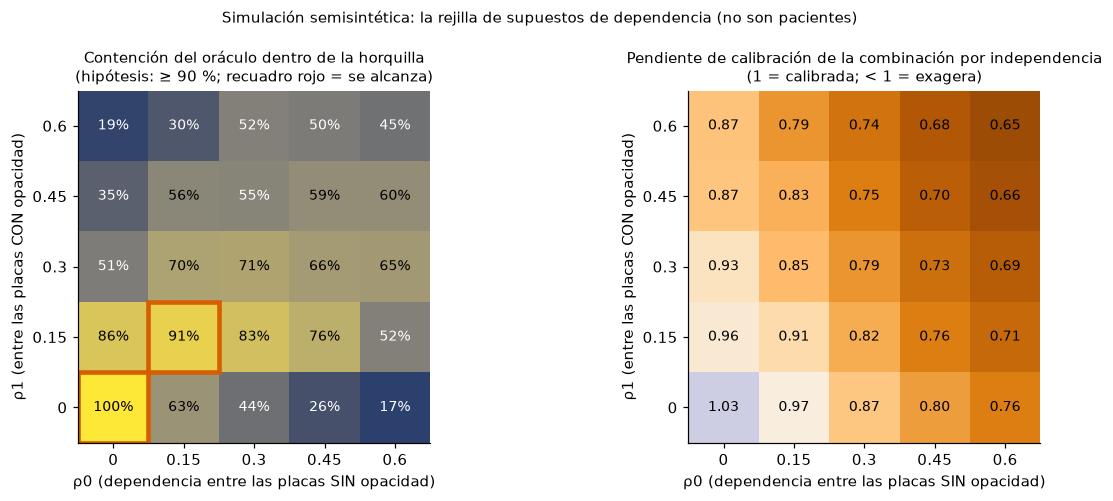

In [10]:
valores = SIM["parametros"]["rejilla"]
contencion = np.full((5, 5), np.nan)
pendiente = np.full((5, 5), np.nan)
for c in SIM["celdas"]:
    i, j = valores.index(c["rho1"]), valores.index(c["rho0"])
    contencion[i, j] = c["horquilla"]["todos"]["contencion"]
    pendiente[i, j] = c["modelos"]["independencia"]["pendiente"]
umbral_h = SIM["parametros"]["hipotesis_contencion"]

fig, ejes = plt.subplots(1, 2, figsize=(11.5, 4.6))
imagen = ejes[0].imshow(contencion, origin="lower", cmap="cividis", vmin=0, vmax=1)
ejes[0].set_title("Contención del oráculo dentro de la horquilla\n(hipótesis: ≥ 90 %; recuadro rojo = se alcanza)", fontsize=10)
for i in range(5):
    for j in range(5):
        v = contencion[i, j]
        ejes[0].text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v < 0.55 else "black")
        if v >= umbral_h:
            ejes[0].add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="#D55E00", lw=3))
norm = TwoSlopeNorm(vmin=0.6, vcenter=1.0, vmax=1.1)
ejes[1].imshow(pendiente, origin="lower", cmap="PuOr", norm=norm)
ejes[1].set_title("Pendiente de calibración de la combinación por independencia\n(1 = calibrada; < 1 = exagera)", fontsize=10)
for i in range(5):
    for j in range(5):
        ejes[1].text(j, i, f"{pendiente[i, j]:.2f}", ha="center", va="center", fontsize=9)
for eje in ejes:
    eje.set_xticks(range(5), [f"{v:g}" for v in valores]); eje.set_yticks(range(5), [f"{v:g}" for v in valores])
    eje.set(xlabel="ρ0 (dependencia entre las placas SIN opacidad)", ylabel="ρ1 (entre las placas CON opacidad)")
    eje.grid(False)
fig.suptitle("Simulación semisintética: la rejilla de supuestos de dependencia (no son pacientes)", fontsize=10)
fig.tight_layout()
plt.show()

In [11]:
sostiene = [c["nombre"] for c in SIM["celdas"] if c["hipotesis"]["se_sostiene"]]
destacadas = [c for c in SIM["celdas"] if c["destacada"]]
print(f"Hipótesis de la horquilla (contención ≥ {umbral_h:.0%}), estimación puntual: se alcanza en {len(sostiene)} de {len(SIM['celdas'])} celdas: {sostiene}")
print(f"De ellas, 0A es la comprobación de la métrica y '(0,15; 0,15)' no tiene intervalo (solo la estimación).")
print(f"En las {len(destacadas)} celdas destacadas, que sí llevan intervalo (1 000 réplicas), no se sostiene en ninguna: contención de "
      + ", ".join(f"{c['nombre']} {c['horquilla']['todos']['contencion']:.0%}" for c in destacadas))
pend = {c["nombre"]: c["modelos"]["independencia"]["pendiente"] for c in destacadas}
print(f"\nPendiente de la combinación por independencia en las destacadas (solo estimación): "
      + ", ".join(f"{k} {v:.2f}" for k, v in pend.items()))
print(f"  menor que 1 (la independencia exagera): {sum(v < 1 for v in pend.values())} de {len(pend)}")
entero_debajo = [c["nombre"] for c in destacadas if c["intervalos"]["modelos.independencia.pendiente"][1] < 1]
print(f"  con el intervalo entero por debajo de 1: {len(entero_debajo)} de {len(pend)}: {entero_debajo}")
dif = [c for c in destacadas if c["nombre"] != "0A"]
print(f"Frente a la imagen sola, ΔAUC de la combinación por independencia: " + ", ".join(
    f"{c['nombre']} {c['pareadas']['independencia']['auc']:+.3f}" for c in dif))
c66 = celdas["(0,6; 0,6)"]
lo66, hi66 = c66["intervalos"]["pareadas.independencia.auc"]
print(f"En (0,6; 0,6) el ΔAUC es {c66['pareadas']['independencia']['auc']:+.3f} con IC {lo66:+.3f} a {hi66:+.3f}: "
      f"{'contiene' if lo66 <= 0 <= hi66 else 'no contiene'} el 0")
print(f"\nSensibilidad al previo: declarar el previo desplegado ({SIM['parametros']['previo_desplegado']:.4f}) en vez de "
      f"{SIM['insumos']['prevalencia']} desplaza todas las posteriores {c0['sensibilidad_al_previo']['desplazamiento_log_odds']:+.2f} en log-odds.")

Hipótesis de la horquilla (contención ≥ 90%), estimación puntual: se alcanza en 2 de 25 celdas: ['0A', '(0,15; 0,15)']
De ellas, 0A es la comprobación de la métrica y '(0,15; 0,15)' no tiene intervalo (solo la estimación).
En las 6 celdas destacadas, que sí llevan intervalo (1 000 réplicas), no se sostiene en ninguna: contención de (0; 0,3) 44%, (0; 0,6) 17%, (0,3; 0) 51%, (0,3; 0,3) 71%, (0,6; 0) 19%, (0,6; 0,6) 45%

Pendiente de la combinación por independencia en las destacadas (solo estimación): (0; 0,3) 0.87, (0; 0,6) 0.76, (0,3; 0) 0.93, (0,3; 0,3) 0.79, (0,6; 0) 0.87, (0,6; 0,6) 0.65
  menor que 1 (la independencia exagera): 6 de 6
  con el intervalo entero por debajo de 1: 5 de 6: ['(0; 0,3)', '(0; 0,6)', '(0,3; 0,3)', '(0,6; 0)', '(0,6; 0,6)']
Frente a la imagen sola, ΔAUC de la combinación por independencia: (0; 0,3) +0.031, (0; 0,6) +0.017, (0,3; 0) +0.031, (0,3; 0,3) +0.019, (0,6; 0) +0.022, (0,6; 0,6) -0.003
En (0,6; 0,6) el ΔAUC es -0.003 con IC -0.008 a +0.003: contiene 

**Lectura.**

- **La aritmética es correcta (0A).** Con dependencia nula, el sistema reproduce la posterior del generador (contención del 100 %, colas en 0) y la combinación **mejora a la imagen sola** en AUC (unas +0,05, con el intervalo entero por encima de 0) y en Brier (baja). Lo único que prueba 0A es que el sistema **calcula lo que dice calcular**; no que sea exacto en pacientes.
- **La horquilla no es una garantía.** La hipótesis que se declaró de antemano («el oráculo queda dentro de la horquilla en ≥ 90 % de los concordantes») **se refuta** en cuanto hay dependencia: se alcanza solo en 0A y en una celda de dependencia suave sin intervalo, y en las seis celdas con intervalo la contención va del 17 % al 71 %. Es un resultado **igual de publicable**: obliga a repensar la cota, no a esconderla. La horquilla del producto es, hay que decirlo, un **indicador de incertidumbre, no un intervalo de cobertura**.
- **La independencia exagera cuando hay dependencia**: la pendiente de calibración de la combinación queda por debajo de 1 en las seis celdas destacadas y, con el intervalo entero por debajo de 1, en cinco de ellas (resultado de arriba): el sistema se muestra más seguro de lo que justifica.
- **La clínica aporta, pero menos cuanto más dependiente:** en la celda extrema (0,6; 0,6) la combinación ya no mejora el AUC de la imagen sola (el intervalo contiene el 0, resultado de arriba).
- **Reserva de fondo:** el generador supone que la distribución de la puntuación en la cohorte de derivación se transporta al espectro de RSNA, que no es una cohorte con sospecha de neumonía. Eso no se puede comprobar aquí.

## 6. La sesión con un médico

Para acercarse a la práctica se hizo una sesión con **un médico general colaborador** (voluntario), sobre **24 casos** de la misma simulación (la placa real, la clínica generada), elegidos con semilla por estratos (positivas claras, negativas claras, bandas contradictorias y asma «no sé»). Dos lecturas: la **primera sin el copiloto** (placa y viñeta; banda y porcentaje) y la **segunda con el mensaje del sistema** en 20 casos y 4 controles sin mensaje. Las bandas son < 20 %, 20-70 % y > 70 % (convención del equipo). **El kappa sale solo de la primera lectura.**

**Desviaciones del protocolo, declaradas en el acta (`acta-h7.md`):** el intervalo entre lecturas fue de **5 días** y no los 7 o más del diseño (con menos días el médico recuerda más los casos); la sesión fue por **videollamada** y el equipo tecleó lo que el médico dictaba; y en la lectura 1 dos casos se marcaron «alta» con un 70 %, que por la convención es intermedia (el kappa usa la banda que eligió el médico).

                           medida  kappa IC 95 % analítico  IC 95 % BCa  n  ≥ 0,4 (valor)  límite inferior < 0,4
kappa ponderado lineal (PRIMARIO)  0.252       0.07 a 0.44  0.11 a 0.49 24          False                   True
     kappa de Cohen, sin ponderar  0.105      -0.09 a 0.30 -0.05 a 0.34 24          False                   True
          kappa binario en «alta»  0.289       0.03 a 0.55  0.09 a 0.65 24          False                   True

Sensibilidad a la regla con que se asigna la categoría del sistema (kappa ponderado): {'independencia': 0.2524590163934425, 'conservador': 0.2524590163934425, 'cruza': 0.2524590163934425}; casos cuya horquilla cruza un límite: 0 de 24

Acuerdo continuo (porcentaje del médico frente a la probabilidad del sistema): Spearman 0.62; diferencia media médico - sistema +2.82 log-odds (DE 2.42); el porcentaje del médico cae dentro de la horquilla del sistema en 0 de 24 casos
  (13 de las 24 horquillas son un solo valor impreso y 5 de ellas una cota «

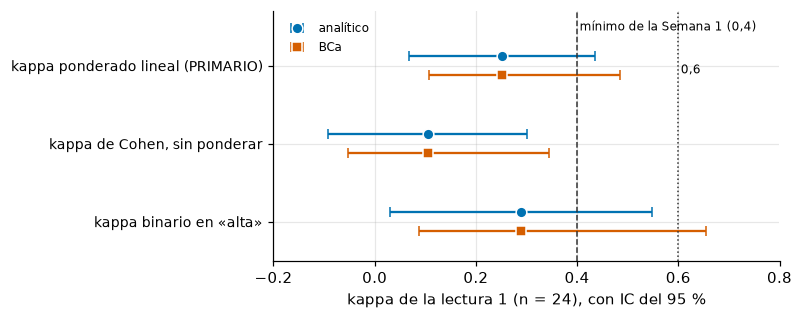

Declarado antes de la sesión: Con 24 casos y un solo evaluador, el intervalo del 95 % del kappa tiene una anchura de 0,5 a 0,6. El diseño no distingue una concordancia moderada (0,4) de una sustancial (0,6), ni generaliza a otros médicos ni a otro reparto de casos, que aquí es deliberado. El criterio ≥ 0,4 de la Semana 1 se evalúa sobre la estimación puntual y se publica siempre con su intervalo; si el límite inferior queda por debajo de 0,4, se dice.


In [12]:
k = SESION["kappa"]
nombres_k = {"ponderado_lineal": "kappa ponderado lineal (PRIMARIO)", "cohen": "kappa de Cohen, sin ponderar", "binario_alta": "kappa binario en «alta»"}
filas = []
for clave, nombre in nombres_k.items():
    v = k[clave]
    filas.append({"medida": nombre, "kappa": round(v["kappa"], 3), "IC 95 % analítico": f"{v['ic95'][0]:.2f} a {v['ic95'][1]:.2f}",
                  "IC 95 % BCa": f"{v['ic95_bca'][0]:.2f} a {v['ic95_bca'][1]:.2f}", "n": v["n"],
                  "≥ 0,4 (valor)": v["frente_a_umbrales"]["puntual_ge_0_4"],
                  "límite inferior < 0,4": v["frente_a_umbrales"]["li_analitico_lt_0_4"] and v["frente_a_umbrales"]["li_bca_lt_0_4"]})
print(pd.DataFrame(filas).to_string(index=False))

print(f"\nSensibilidad a la regla con que se asigna la categoría del sistema (kappa ponderado): {SESION['sensibilidad_categoria']}; "
      f"casos cuya horquilla cruza un límite: {SESION['n_cruzan_un_limite']} de {SESION['n']}")
ac = SESION["acuerdo_continuo"]
print(f"\nAcuerdo continuo (porcentaje del médico frente a la probabilidad del sistema): Spearman {ac['spearman']:.2f}; "
      f"diferencia media médico - sistema {ac['diferencia_media_log_odds']:+.2f} log-odds (DE {ac['de']:.2f}); "
      f"el porcentaje del médico cae dentro de la horquilla del sistema en {ac['dentro_de_la_horquilla']} de {SESION['n']} casos")
print(f"  ({ac['horquillas_de_anchura_cero']} de las {SESION['n']} horquillas son un solo valor impreso y {ac['horquillas_que_son_una_cota']} de ellas una cota «< 1 %» o «> 99 %»)")

fig, eje = plt.subplots(figsize=(7.4, 3.0))
for y, (clave, nombre) in enumerate(list(nombres_k.items())[::-1]):
    v = k[clave]
    eje.errorbar(v["kappa"], y + 0.12, xerr=[[v["kappa"] - v["ic95"][0]], [v["ic95"][1] - v["kappa"]]], fmt="o", color="#0072B2", capsize=3, ms=7, mec="white", label="analítico" if y == 0 else None)
    eje.errorbar(v["kappa"], y - 0.12, xerr=[[v["kappa"] - v["ic95_bca"][0]], [v["ic95_bca"][1] - v["kappa"]]], fmt="s", color="#D55E00", capsize=3, ms=6, mec="white", label="BCa" if y == 0 else None)
eje.axvline(0.4, color="#333333", ls="--", lw=1); eje.axvline(0.6, color="#333333", ls=":", lw=1)
eje.text(0.405, 2.45, "mínimo de la Semana 1 (0,4)", fontsize=8); eje.text(0.605, 1.9, "0,6", fontsize=8)
eje.set_yticks(range(3), [nombres_k[c] for c in list(nombres_k)[::-1]], fontsize=9)
eje.set(xlim=(-0.2, 0.8), ylim=(-0.5, 2.7), xlabel="kappa de la lectura 1 (n = 24), con IC del 95 %")
eje.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()
print("Declarado antes de la sesión:", SESION["texto_fijado"])

In [13]:
orden_banda = {"baja": 0, "intermedia": 1, "alta": 2}
desacuerdos = SESION["desacuerdos"]
cruce = Counter((d["sistema"], d["medico"]) for d in desacuerdos)
medico_mas_alto = sum(orden_banda[d["medico"]] > orden_banda[d["sistema"]] for d in desacuerdos)
print(f"Casos en que el médico y el sistema discrepan de banda: {len(desacuerdos)} de {SESION['n']}; "
      f"en {medico_mas_alto} de ellos el médico puso una banda MÁS ALTA que el sistema.")
print("sistema -> médico:", {f"{s} -> {m}": n for (s, m), n in sorted(cruce.items())})

# Los casos por estrato salen del anexo del acta; solo se cuentan, no se muestran.
acta = (DOCS / "acta-h7.md").read_text(encoding="utf-8")
anexo = acta.split("## Anexo: los casos")[-1]
estratos = Counter(re.findall(r"^\| [0-9a-f]{8}-[0-9a-f-]{27} \| ([^|]+?) \| ", anexo, flags=re.M))
por_estrato = Counter(d["estrato"].replace("_", " ").replace("asma no se", "asma «no sé»") for d in desacuerdos)
print("\nDesacuerdos por estrato (de los casos de cada estrato):")
for estrato, total in estratos.items():
    clave = estrato.replace("asma «no sé»", "asma «no sé»")
    print(f"  {estrato:<22} {por_estrato.get(clave, 0)} de {total}")

Casos en que el médico y el sistema discrepan de banda: 16 de 24; en 16 de ellos el médico puso una banda MÁS ALTA que el sistema.
sistema -> médico: {'baja -> alta': 3, 'baja -> intermedia': 7, 'intermedia -> alta': 6}

Desacuerdos por estrato (de los casos de cada estrato):
  positiva clara         3 de 8
  negativa clara         5 de 8
  banda contradictoria   4 de 4
  asma «no sé»           4 de 4


Lectura 2, con el mensaje del sistema delante (20 casos con mensaje y 4 controles sin él):
  kappa con el mensaje delante 0.81 (IC analítico 0.61 a 1.00; BCa 0.53 a 1.00) -> es INFLUENCIA del sistema, no concordancia independiente
  cambió de banda en 12 de 20 casos

Utilidad del pre-informe (1 a 5, n = 20): corrección 4.65, utilidad 4.05, lenguaje 2.55
Tiempo de triaje: razón con/sin copiloto 2.00 (IC BCa 1.57 a 2.49); controles releídos sin copiloto: media geométrica 1.80 (n = 4); razón corregida por releer 1.11 (IC 0.69 a 1.81)


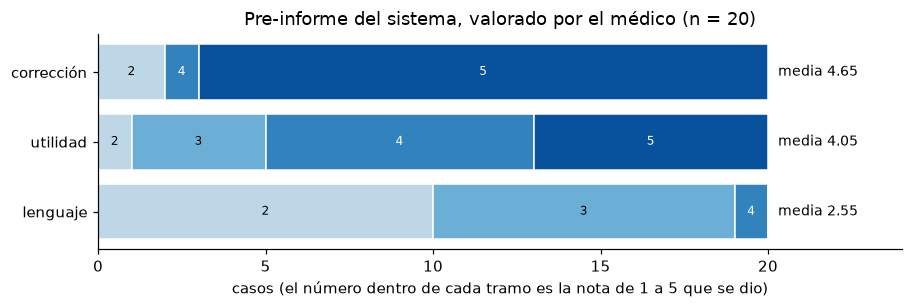

In [14]:
l2 = SESION["lectura2"]
kc = l2["kappa_con_mensaje"]
print(f"Lectura 2, con el mensaje del sistema delante ({l2['n_con_mensaje']} casos con mensaje y {l2['n_controles']} controles sin él):")
print(f"  kappa con el mensaje delante {kc['kappa']:.2f} (IC analítico {kc['ic95'][0]:.2f} a {kc['ic95'][1]:.2f}; BCa {kc['ic95_bca'][0]:.2f} a {kc['ic95_bca'][1]:.2f}) "
      f"-> es INFLUENCIA del sistema, no concordancia independiente")
print(f"  cambió de banda en {l2['cambios_de_banda']} de {l2['n_con_mensaje']} casos")

u = l2["utilidad"]
t = l2["tiempo"]
print(f"\nUtilidad del pre-informe (1 a 5, n = {u['correccion']['n']}): corrección {u['correccion']['media']:.2f}, "
      f"utilidad {u['utilidad']['media']:.2f}, lenguaje {u['lenguaje']['media']:.2f}")
print(f"Tiempo de triaje: razón con/sin copiloto {t['razon_medias_geometricas']:.2f} (IC BCa {t['ic95_bca'][0]:.2f} a {t['ic95_bca'][1]:.2f}); "
      f"controles releídos sin copiloto: media geométrica {t['controles']['media_geometrica']:.2f} (n = {t['controles']['n']}); "
      f"razón corregida por releer {t['razon_corregida_por_releer']:.2f} (IC {t['ic95_razon_corregida'][0]:.2f} a {t['ic95_razon_corregida'][1]:.2f})")

fig, eje = plt.subplots(figsize=(8.4, 2.9))
colores = ["#EFF3FF", "#BDD7E7", "#6BAED6", "#3182BD", "#08519C"]
for y, (clave, nombre) in enumerate((("lenguaje", "lenguaje"), ("utilidad", "utilidad"), ("correccion", "corrección"))):
    d = u[clave]["distribucion"]
    inicio = 0
    for nota, color in zip("12345", colores):
        n = d[nota]
        eje.barh(y, n, left=inicio, color=color, edgecolor="white")
        if n:
            eje.text(inicio + n / 2, y, str(nota), ha="center", va="center", fontsize=8, color="white" if int(nota) >= 4 else "black")
        inicio += n
    eje.text(inicio + 0.3, y, f"media {u[clave]['media']:.2f}", va="center", fontsize=9)
eje.set_yticks(range(3), ["lenguaje", "utilidad", "corrección"])
eje.set(xlim=(0, 24), xlabel="casos (el número dentro de cada tramo es la nota de 1 a 5 que se dio)", title="Pre-informe del sistema, valorado por el médico (n = 20)")
eje.grid(False)
fig.tight_layout()
plt.show()

**Lectura.**

- **El acuerdo del médico con el sistema es bajo.** El kappa ponderado de la lectura 1 (**0,25**) **no alcanza el 0,4** mínimo de la Semana 1, y el límite inferior de su intervalo queda por debajo de 0,4 con los dos métodos; el de Cohen sin ponderar (0,10) y el binario en «alta» (0,29) tampoco. Pero el intervalo del kappa ponderado (0,07 a 0,44 el analítico, 0,11 a 0,49 el BCa) **contiene el 0,4** y deja fuera el 0,6: con 24 casos y un solo evaluador **no se puede descartar una concordancia moderada, ni se puede afirmar**, y el resultado no generaliza a otros médicos ni a otro reparto de casos.
- **Cómo discrepan:** en **todos** los casos en que difieren, el médico pone una banda **más alta** que el sistema. De los 5 desacuerdos en negativas claras, 4 son «baja» frente a «intermedia». Y los **8 casos de bandas contradictorias y de asma «no sé» discreparon todos** (los desacuerdos se concentran donde clínica e imagen se contradicen o falta un dato). El acta no recoge comentarios que expliquen por qué (el campo está vacío; el sistema usó la prevalencia local declarada, 0,1466): no se puede decir cuál de los dos acierta más, solo que **no coinciden y siempre en el mismo sentido**.
- **Con el mensaje delante el acuerdo sube (kappa 0,81) y el médico cambió de banda en 12 de 20 casos:** es la **influencia** del sistema, no concordancia independiente. El propio acta advierte que, entre los 4 controles releídos sin mensaje, 3 cambiaron de banda solo por releer; con menos de 7 días entre lecturas, ese efecto pesa.
- **El pre-informe: correcto y útil, pero su lenguaje flojea.** La corrección (4,65 de 5) y la utilidad (4,05) son altas; el **lenguaje** (**2,55**, la mitad de los casos con un 2) es el punto débil. Es lo que hay que arreglar antes de llevarlo a la práctica.
- **El tiempo no mejoró, ni se puede decir que empeorara por culpa del copiloto:** la razón de medias geométricas con/sin copiloto es 2,0 (el triaje con mensaje tardó el doble), pero los controles muestran que releer ya cambia el tiempo; corregida por releer, la razón queda en 1,1 con un intervalo (0,69 a 1,81) **que contiene el 1**. Además el tiempo incluye el tecleo del equipo por videollamada. **No hay evidencia de ahorro de tiempo.**

## 7. Dónde falla el sistema, y qué se puede afirmar

| Fallo | Evidencia (en este cuaderno) | Qué implica | Estado |
| :--- | :--- | :--- | :--- |
| **El sesgo de la vista**: con un solo umbral se comporta como dos clasificadores | PA: recall 0,69 (IC entero bajo el mínimo); AP: especificidad 0,39 (IC entero bajo el mínimo) (§3) | en PA se escapan casi un tercio de las opacidades; en AP se marca más de la mitad de las placas sanas | umbral por vista **evaluado y apagado**: iguala el recall pero cuesta especificidad global (§4) |
| **La especificidad global está en el mínimo, no sobre él** | 0,702, IC 0,686 a 0,719: contiene el 0,70 (§2) | no se puede afirmar que cumpla el mínimo | declarado; el objetivo de 0,75 es inalcanzable a la vez que el recall objetivo (cuaderno 04, §7) |
| **Los mayores de 60 años** | recall 0,83 (IC 0,77 a 0,88), AUC 0,85, el más bajo de los tramos (§3) | puede rendir peor; no se puede afirmar con estas muestras | sin mitigación |
| **Precisión baja** | menos de la mitad de las placas marcadas tienen opacidad; una de cada tres con la prevalencia local declarada (§2) | muchas revisiones de más: es cribado, no diagnóstico | el profesional decide siempre |
| **La horquilla de la combinación no cubre** bajo dependencia | contención ≥ 90 % solo en 0A y en una celda sin intervalo; 17 % a 71 % en las destacadas (§5) | la horquilla es un indicador, no una garantía de cobertura | declarado; la independencia exagera con dependencia |
| **Poco acuerdo con el médico** | kappa ponderado 0,25 < 0,4; en los 16 desacuerdos el médico pone más alto (§6) | el mensaje del sistema y el juicio del médico no coinciden | declarado; un solo médico y 24 casos |
| **El lenguaje del pre-informe** | 2,55 de 5, el más bajo de los tres criterios (§6) | el médico valoró bajo el lenguaje del texto: hay que mejorarlo antes de usarlo | pendiente |
| **Sin ahorro de tiempo demostrado** | razón 2,0; corregida por releer, 1,1 con IC que contiene el 1 (§6) | no hay evidencia de que acelere el triaje | sin resolver: haría falta otra sesión, con otro diseño |
| **La etiqueta** | RSNA marca *opacidad pulmonar*, no neumonía confirmada | el sistema detecta opacidades, no diagnostica | declarado en el cuaderno 02 (§10) |

**Qué se puede afirmar:** que el modelo de imagen ordena bien las placas de RSNA (AUC 0,885; 0,88 dentro de PA y 0,83 dentro de AP), que su probabilidad calibrada es fiable en esas placas, que la combinación calcula lo que dice calcular (0A) y que el sistema funciona como **cribado** sobre ese conjunto con recall alrededor de 0,88.

**Qué NO se puede afirmar:** exactitud clínica en pacientes; que sirva en otra población, en otros equipos o con otros médicos (no hay validación externa); que la clínica aporte en la práctica lo que aporta en la simulación (las viñetas no son pacientes); que ahorre tiempo; ni que la horquilla cubra la verdad cuando clínica e imagen son dependientes.